# 09 · Results

This notebook joins the six strategies and answers the three questions of the study. All the rules used here were fixed before running the experiment (12-Oct-2026). Nothing is trained here.

The three questions are the following:
1. **Which AUC does each strategy reach?** Measured as the mean AUC on the exam.
2. **Which strategy is more stable?** Measured as the SD of the AUC across the 100 repetitions. This is the main outcome of the study.
3. **How many local patients are needed for fine-tuning to pay off?** Measured as the first n with an AUC higher than applying the source model directly.

Everything is computed separately in CPTAC and in SMC 2018. When both cohorts agree, the result is replicated.

| # | Strategy | What it learns from |
|---|---|---|
| 1 | Network: apply directly | Only the source (TCGA + METABRIC) |
| 2 | Network: fine-tuning | Network 1, adjusted with n local patients |
| 3 | Network: from scratch | Only the n local patients |
| 4 | ElasticNet: apply directly | Only the source |
| 5 | ElasticNet local | Only the n local patients |
| 6 | ElasticNet source + local | The source and the n local patients together (local patients = 50% of the weight) |

**Input** (in `data/experiment/`): `auc_elasticnet.csv` and `prob_elasticnet.parquet` (notebook 05), `auc_red.csv` and `prob_red.parquet` (notebook 08). The PCA figure also reads the expression of the four cohorts.

**Output:** tables in `results/tables/09_*.csv` and figures in `results/figures/09_*.png`.

Column names inside the data files are in Spanish: `cohorte` = cohort, `examen` = exam, `estrategia` = strategy, `repeticion` = repetition, `muestra` = sample, `peso_locales` = weight of the local patients, `variante` = fine-tuning setting (`principal` = main, `sensibilidad` = sensitivity).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import false_discovery_control
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import DATA, FILES, cargar, pitman_morgan, stouffer, zscore

EXP = ROOT / "data" / "experiment"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"

TARGETS = ["CPTAC", "SMC 2018"]
NAMES = {1: "1. Network: apply directly", 2: "2. Network: fine-tuning", 3: "3. Network: from scratch",
         4: "4. ElasticNet: apply directly", 5: "5. ElasticNet local", 6: "6. ElasticNet source + local"}
NET, ENET = "#534AB7", "#D85A30"
STYLE = {2: (NET, "-", "o"), 3: (NET, "--", "s"), 5: (ENET, "--", "s"), 6: (ENET, "-", "o")}
LOCAL = [2, 3, 5, 6]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Step 1 · Join the results

The main analysis uses strategy 6 with the local patients at 50% of the weight, and strategy 2 with its main setting (learning rate 1e-5, 10 epochs). The other versions (weights of 10% and 25%, and fine-tuning with learning rate 1e-4) are sensitivity analyses. They are in step 6.

In [2]:
enet = pd.read_csv(EXP / "auc_elasticnet.csv")
red = pd.read_csv(EXP / "auc_red.csv")
keys = ["cohorte", "examen", "estrategia", "n", "repeticion"]
main = pd.concat([enet[enet.peso_locales.isna() | (enet.peso_locales == 0.5)][keys + ["auc"]],
                  red[red.variante == "principal"][keys + ["auc"]]], ignore_index=True)

counts = main.groupby(["cohorte", "estrategia", "n"]).size()
assert counts[counts.index.get_level_values("estrategia").isin([1, 4])].eq(5).all()
assert counts[counts.index.get_level_values("estrategia").isin(LOCAL)].eq(500).all()
print(f"{len(main):,} AUCs: 1 per exam for strategies 1 and 4; 100 per exam and n for the others")

18,020 AUCs: 1 per exam for strategies 1 and 4; 100 per exam and n for the others


## Step 2 · Question 1: which AUC does each strategy reach?

For each cohort, strategy and n: the mean AUC of the 5 exams, and the SD across repetitions. The SD is computed inside each exam (100 repetitions) and then averaged over the 5 exams.

In [3]:
def summarize(df):
    per_exam = df.groupby(["cohorte", "estrategia", "n", "examen"]).auc.agg(["mean", "std"])
    return (per_exam.groupby(["cohorte", "estrategia", "n"]).mean()
            .rename(columns={"mean": "mean AUC", "std": "SD across repetitions"}))


summary = summarize(main)
summary.round(3).to_csv(TAB / "09_summary.csv")
summary.round(3)

mean AUC  SD across repetitions
cohorte  estrategia n                                  
CPTAC    1          0      0.933                    NaN
         2          10     0.933                  0.001
                    15     0.933                  0.001
                    20     0.933                  0.001
                    40     0.933                  0.000
         3          10     0.789                  0.116
                    15     0.820                  0.088
                    20     0.841                  0.070
                    40     0.880                  0.040
         4          0      0.930                    NaN
         5          10     0.714                  0.157
                    15     0.764                  0.141
                    20     0.815                  0.111
                    40     0.879                  0.041
         6          10     0.931                  0.010
                    15     0.932                  0.011
                    20     0.931                  0.012
                    40     0.931                  0.010
SMC 2018 1          0      0.866                    NaN
         2          10     0.867                  0.002
                    15     0.867                  0.002
                    20     0.867                  0.002
                    40     0.867                  0.001
                    80     0.866                  0.001
         3          10     0.677                  0.093
                    15     0.702                  0.072
                    20     0.718                  0.065
                    40     0.753                  0.050
                    80     0.772                  0.030
         4          0      0.865                    NaN
         5          10     0.654                  0.116
                    15     0.695                  0.108
                    20     0.731                  0.081
                    40     0.773                  0.048
                    80     0.791                  0.026
         6          10     0.853                  0.015
                    15     0.852                  0.015
                    20     0.851                  0.016
                    40     0.846                  0.016
                    80     0.834                  0.014

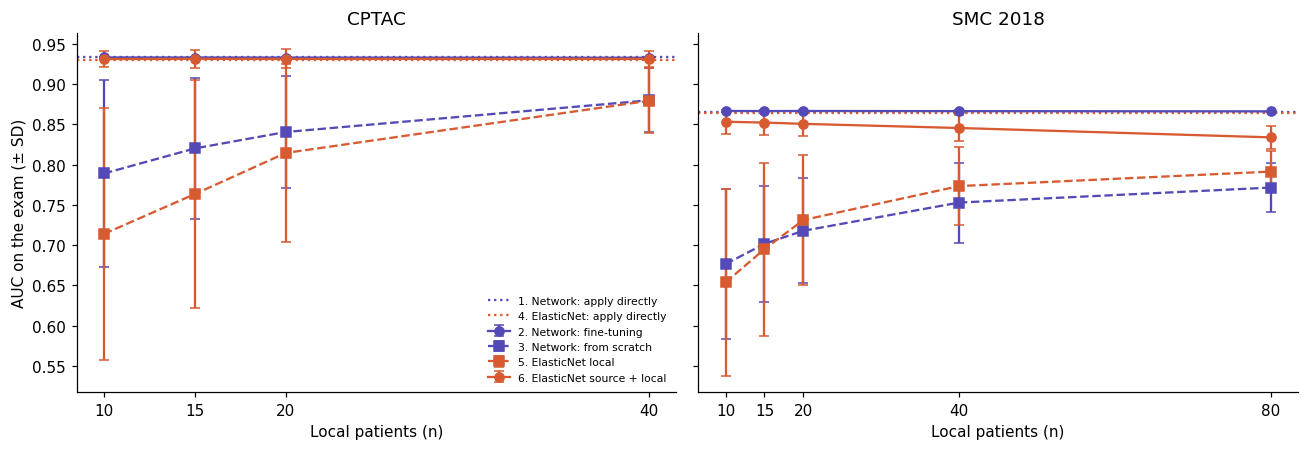

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name in zip(axes, TARGETS):
    s = summary.loc[name]
    for k in LOCAL:
        color, ls, marker = STYLE[k]
        t = s.loc[k]
        ax.errorbar(t.index, t["mean AUC"], yerr=t["SD across repetitions"], color=color, ls=ls, marker=marker,
                    capsize=3, label=NAMES[k])
    ax.axhline(s.loc[(1, 0), "mean AUC"], color=NET, ls=":", lw=1.5, label=NAMES[1])
    ax.axhline(s.loc[(4, 0), "mean AUC"], color=ENET, ls=":", lw=1.5, label=NAMES[4])
    ax.set_title(name)
    ax.set_xlabel("Local patients (n)")
    ax.set_xticks(s.loc[2].index)
axes[0].set_ylabel("AUC on the exam (± SD)")
axes[0].legend(frameon=False, fontsize=7, loc="lower right")
plt.tight_layout()
fig.savefig(FIG / "09_auc_vs_n.png", bbox_inches="tight")

**Figure 09-1 · How to read it:** each point is the mean AUC with n local patients. The bars show how much it changes depending on which patients were drawn. The dotted lines are "apply directly", which uses no local patient with a known TP53 status (n = 0). Purple = network; orange = ElasticNet. Solid line = uses the source; dashed line = uses only the local patients.

## Step 3 · Question 2: which strategy is more stable?

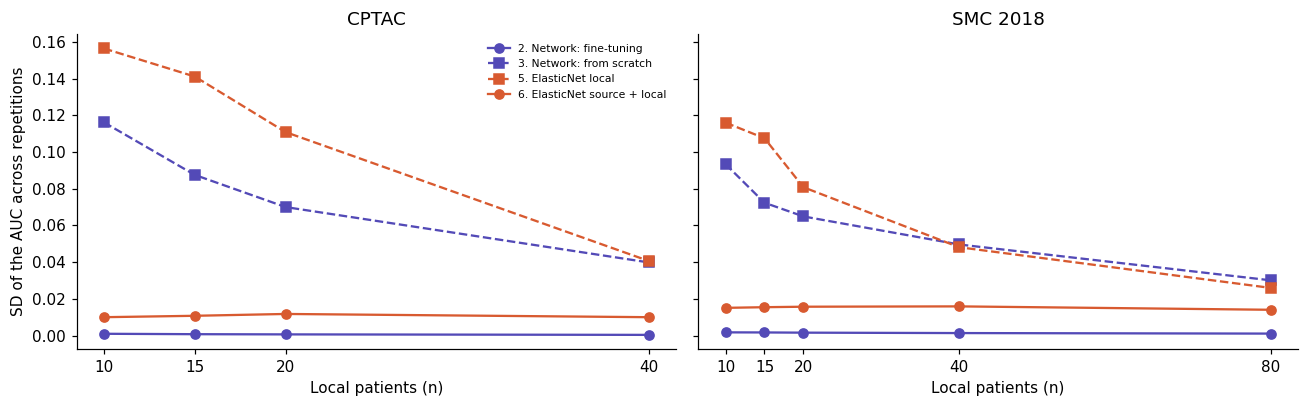

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, TARGETS):
    for k in LOCAL:
        color, ls, marker = STYLE[k]
        t = summary.loc[(name, k)]
        ax.plot(t.index, t["SD across repetitions"], color=color, ls=ls, marker=marker, label=NAMES[k])
    ax.set_title(name)
    ax.set_xlabel("Local patients (n)")
    ax.set_xticks(summary.loc[(name, 2)].index)
axes[0].set_ylabel("SD of the AUC across repetitions")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(FIG / "09_sd_vs_n.png", bbox_inches="tight")

**Figure 09-2 · How to read it:** lower = more stable. In other words, the AUC depends less on which patients were drawn. Strategies 1 and 4 are not shown because they use no local patients, so their SD is 0.

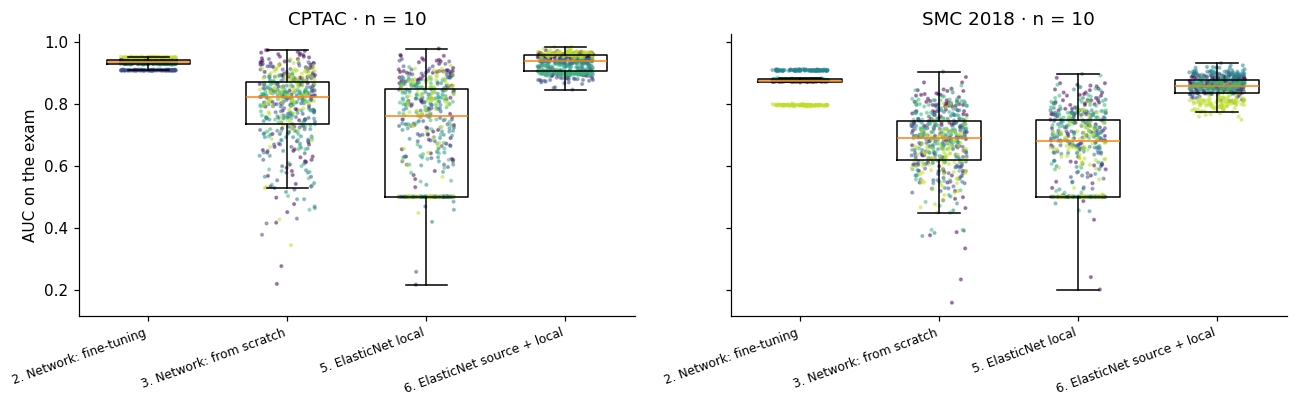

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
for ax, name in zip(axes, TARGETS):
    d = main[(main.cohorte == name) & (main.n == 10)]
    for i, k in enumerate(LOCAL):
        v = d[d.estrategia == k]
        ax.boxplot(v.auc, positions=[i], widths=0.6, showfliers=False)
        ax.scatter(i + np.random.default_rng(0).uniform(-0.2, 0.2, len(v)), v.auc, s=3, alpha=0.4,
                   c=[colors[e - 1] for e in v.examen])
    ax.set_xticks(range(4), [NAMES[k] for k in LOCAL], rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{name} · n = 10")
axes[0].set_ylabel("AUC on the exam")
plt.tight_layout()
fig.savefig(FIG / "09_boxes_n10.png", bbox_inches="tight")

**Figure 09-3 · How to read it:** each point is one repetition (500 per strategy: 5 exams × 100). The color shows the exam. A short box means that the result barely depends on which 10 patients were drawn.

In fine-tuning, the points form one horizontal band per exam. The bands are at different heights because each exam has different patients. This figure mixes two kinds of variation, and the next one separates them.

### The same boxes, centered by exam

The previous figure mixes two variations. The first one is the variation across repetitions inside an exam, which is what the SD measures. The second one is the variation across exams, because each exam has 40 different patients. Here, the mean of its exam is subtracted from each AUC. This way only the variation across repetitions is left. Fine-tuning with learning rate 1e-4 (sensitivity) is added.

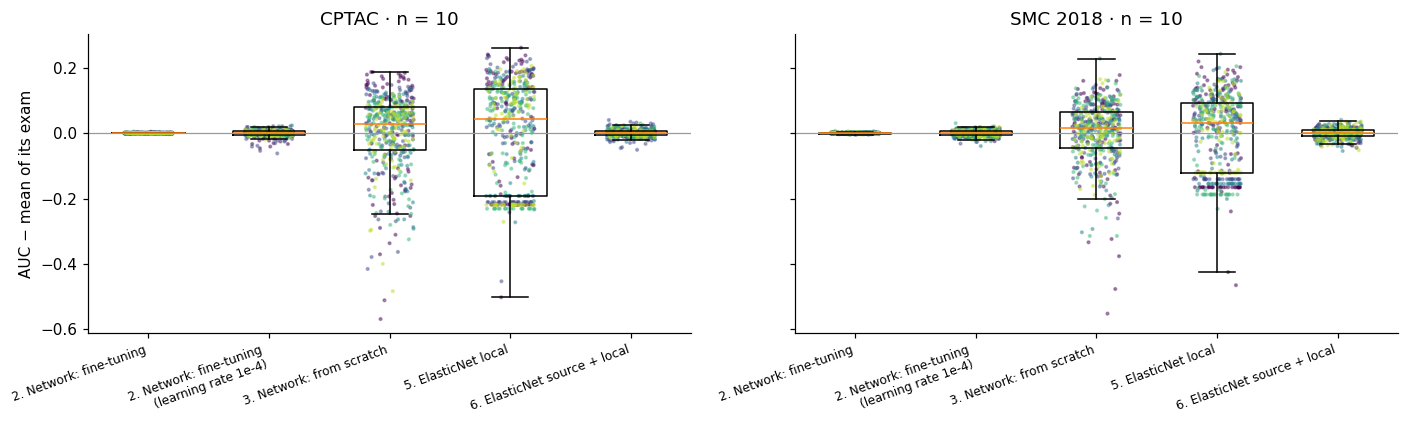

In [7]:
sens_ft = red[(red.estrategia == 2) & (red.variante == "sensibilidad")][keys + ["auc"]].assign(estrategia="2s")
boxes = [2, "2s", 3, 5, 6]
labels = {**NAMES, "2s": "2. Network: fine-tuning\n(learning rate 1e-4)"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = pd.concat([main, sens_ft])
    d = d[(d.cohorte == name) & (d.n == 10)].copy()
    d["centered"] = d.auc - d.groupby(["estrategia", "examen"]).auc.transform("mean")
    for i, k in enumerate(boxes):
        v = d[d.estrategia == k]
        ax.boxplot(v.centered, positions=[i], widths=0.6, showfliers=False)
        ax.scatter(i + np.random.default_rng(0).uniform(-0.2, 0.2, len(v)), v.centered, s=3, alpha=0.4,
                   c=[colors[e - 1] for e in v.examen])
    ax.axhline(0, color="#999999", lw=0.8)
    ax.set_xticks(range(len(boxes)), [labels[k] for k in boxes], rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{name} · n = 10")
axes[0].set_ylabel("AUC − mean of its exam")
plt.tight_layout()
fig.savefig(FIG / "09_boxes_n10_centered.png", bbox_inches="tight")

**Figure 09-3b · How to read it:** 0 is the mean AUC of each exam. The width of the box shows how much the AUC changes only because of which 10 patients were drawn.

Two things are worth explaining:
1. **Main fine-tuning is a line at 0.** The network does change: its loss on the 10 local patients goes from 0.81 to 0.69. But the probability of each exam patient changes in the fourth decimal (median 0.00014). The AUC only changes when one mutated/not mutated pair swaps its order. In a CPTAC exam there are 16 × 24 = 384 pairs, so one swap moves the AUC by 1/384 = 0.0026. That is why main fine-tuning gives only 2 to 6 different AUC values per exam. With learning rate 1e-4 it gives 16 to 29.
2. **ElasticNet local has a band at AUC = 0.5.** With n = 10, 25% of the models give an AUC of exactly 0.5. This happens when the internal cross-validation chooses the strongest penalty. Every gene ends up with a weight of 0, and the model gives the same probability to every patient.

### Primary comparisons (n = 10, not corrected)

1. **Strategy 2 vs 3:** does pretraining make the network more stable?
2. **Strategy 2 vs 6:** is the network more stable than the ElasticNet that also uses the source?

In each exam, the **Pitman-Morgan test** compares the SD of the two strategies over the 100 paired repetitions (same patients). It gives a z value that is positive when strategy 2 has the smaller SD. The 5 exams are joined with the **Stouffer method** (sum of z / √5), two-sided. The result is significant when |Z| > 1.96.

**SD reduction (%)** = (1 − SD of strategy 2 / SD of the other strategy) × 100. It says by which percentage strategy 2 varies less. The range across the 5 exams is also given. A negative value means that strategy 2 varied more.

In [8]:
def compare(df, a, b, n, name):
    rows = []
    for e in range(1, 6):
        d = df[(df.cohorte == name) & (df.n == n) & (df.examen == e)]
        x = d[d.estrategia == a].set_index("repeticion").auc
        y = d[d.estrategia == b].set_index("repeticion").auc.loc[x.index]
        p, z = pitman_morgan(x, y)
        rows.append({"exam": e, "sd_a": x.std(), "sd_b": y.std(), "z": z, "p": p})
    r = pd.DataFrame(rows)
    Z, P = stouffer(r.z)
    cut = 100 * (1 - r.sd_a / r.sd_b)  # % by which the SD of strategy a is smaller than the SD of b, in each exam
    return {"cohort": name, "comparison": f"{a} vs {b}", "n": n, "SD strategy a": r.sd_a.mean(),
            "SD strategy b": r.sd_b.mean(), "SD ratio (b / a)": r.sd_b.mean() / r.sd_a.mean(),
            "SD reduction (%)": 100 * (1 - r.sd_a.mean() / r.sd_b.mean()),
            "min reduction (%)": cut.min(), "max reduction (%)": cut.max(),
            **{f"z exam {e}": z for e, z in zip(r.exam, r.z)}, "combined Z": Z, "p": P}


PRIMARY = [(2, 3), (2, 6)]
primary = pd.DataFrame([compare(main, a, b, 10, name) for name in TARGETS for a, b in PRIMARY])
primary.round(4).to_csv(TAB / "09_primary.csv", index=False)
primary.round(4)

,cohort,comparison,n,SD strategy a,SD strategy b,SD ratio (b / a),SD reduction (%),min reduction (%),max reduction (%),z exam 1,z exam 2,z exam 3,z exam 4,z exam 5,combined Z,p
0,CPTAC,2 vs 3,10,0.0009,0.1162,123.0319,99.1872,98.9758,99.6290,45.5381,49.7406,45.1256,45.8156,55.1306,107.9352,0.0
1,CPTAC,2 vs 6,10,0.0009,0.0100,10.5734,90.5423,78.1789,95.5470,15.6293,30.6524,20.4784,23.7470,29.5506,53.6914,0.0
2,SMC 2018,2 vs 3,10,0.0017,0.0935,54.2954,98.1582,97.1527,99.0133,45.5876,35.0506,39.6255,38.2671,37.6631,87.7405,0.0
3,SMC 2018,2 vs 6,10,0.0017,0.0151,8.7615,88.5864,81.2020,91.6826,24.5120,18.6783,23.4483,16.4936,23.8511,47.8444,0.0


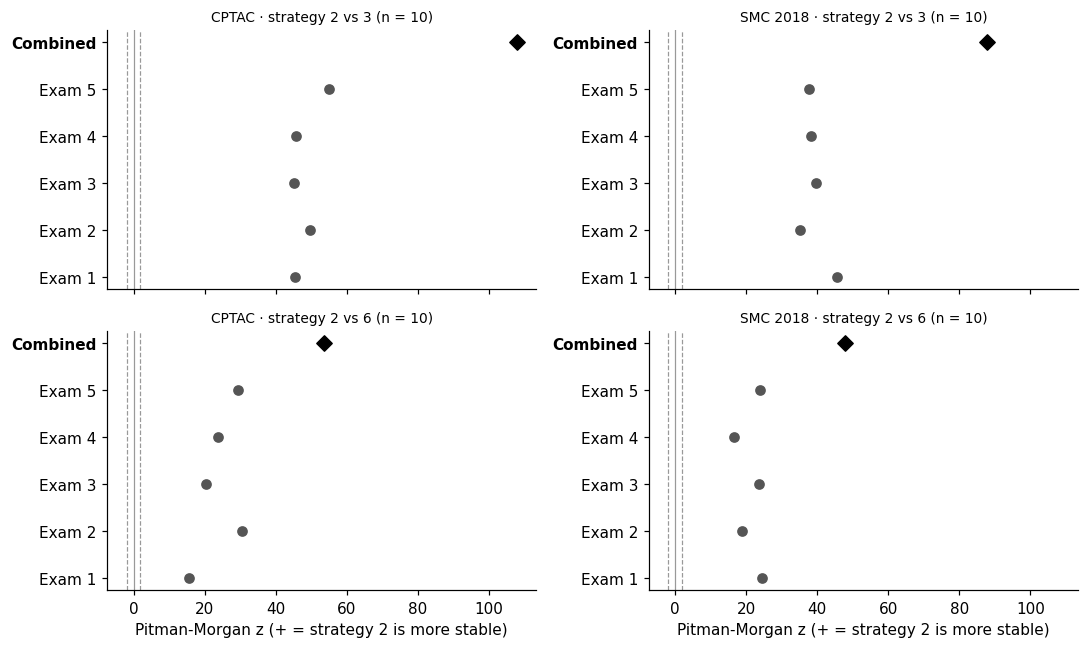

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for i, (a, b) in enumerate(PRIMARY):
    for j, name in enumerate(TARGETS):
        ax = axes[i, j]
        r = primary[(primary.cohort == name) & (primary.comparison == f"{a} vs {b}")].iloc[0]
        zs = [r[f"z exam {e}"] for e in range(1, 6)] + [r["combined Z"]]
        ax.scatter(zs[:5], range(5), color="#555555")
        ax.scatter(zs[5], 5, color="black", marker="D", s=50)
        for x in (-1.96, 0, 1.96):
            ax.axvline(x, color="#999999", lw=0.8, ls="-" if x == 0 else "--")
        ax.set_yticks(range(6), [f"Exam {e}" for e in range(1, 6)] + ["Combined"])
        ax.get_yticklabels()[5].set_fontweight("bold")
        ax.set_title(f"{name} · strategy {a} vs {b} (n = 10)", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Pitman-Morgan z (+ = strategy 2 is more stable)")
plt.tight_layout()
fig.savefig(FIG / "09_forest_primary.png", bbox_inches="tight")

**Figure 09-4 · How to read it:** each gray point is one exam, and the black diamond is the combined result of the 5 exams (Stouffer). To the right of +1.96, strategy 2 is significantly more stable. To the left of −1.96, it is significantly less stable. When the 5 exams fall on the same side, the result is consistent.

It is important to mention that in 5 of the 45 combinations of exam and n, main fine-tuning gave the same AUC in all 100 repetitions (SD = 0). In those cases the z is capped (|z| ≈ 71). That is why the SD ratio and the p value describe the result better than Z.

### Paired difference, repetition by repetition

In each repetition both strategies used the same patients. That is why their AUCs can be subtracted directly.

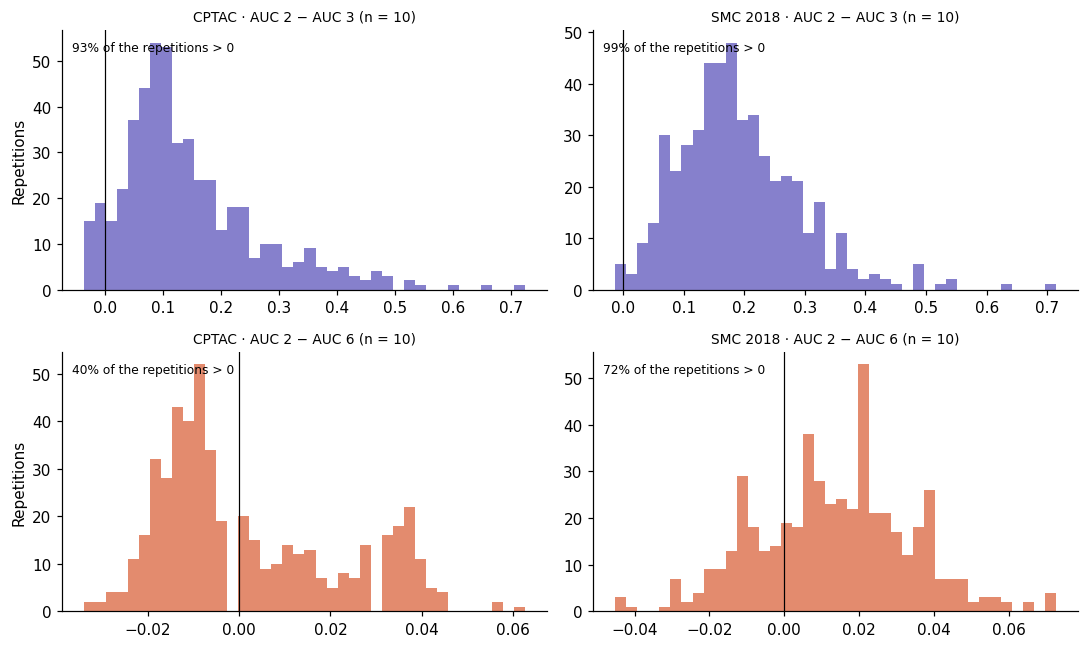

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for i, (a, b) in enumerate(PRIMARY):
    for j, name in enumerate(TARGETS):
        d = main[(main.cohorte == name) & (main.n == 10)].pivot_table(index=["examen", "repeticion"], columns="estrategia", values="auc")
        diff = d[a] - d[b]
        ax = axes[i, j]
        ax.hist(diff, bins=40, color=NET if b == 3 else ENET, alpha=0.7)
        ax.axvline(0, color="black", lw=0.8)
        ax.set_title(f"{name} · AUC {a} − AUC {b} (n = 10)", fontsize=9)
        ax.text(0.02, 0.92, f"{100 * (diff > 0).mean():.0f}% of the repetitions > 0", transform=ax.transAxes, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Repetitions")
plt.tight_layout()
fig.savefig(FIG / "09_paired_difference.png", bbox_inches="tight")

**Figure 09-5 · How to read it:** each bar counts repetitions (500: 5 exams × 100). To the right of 0, strategy 2 had a higher AUC than the other strategy with the same patients. The percentage at the top says in how many repetitions that happened.

### Supporting comparisons

Every pair of strategies 2, 3, 5 and 6, at every n, except the two primary comparisons. The calculation is the same. Since there are many tests, the p values are corrected with **Benjamini-Hochberg**.

In [11]:
pairs = [(a, b) for i, a in enumerate(LOCAL) for b in LOCAL[i + 1:]]
support = pd.DataFrame([compare(main, a, b, n, name) for name in TARGETS for a, b in pairs
                        for n in sorted(main[main.cohorte == name].n.unique()) if n > 0
                        and not (n == 10 and (a, b) in PRIMARY)])
support["BH-adjusted p"] = false_discovery_control(support.p)
support.round(4).to_csv(TAB / "09_supporting.csv", index=False)
support[["cohort", "comparison", "n", "SD strategy a", "SD strategy b", "SD reduction (%)", "combined Z", "BH-adjusted p"]].round(4)

,cohort,comparison,n,SD strategy a,SD strategy b,SD reduction (%),combined Z,BH-adjusted p
0,CPTAC,2 vs 3,15,0.0007,0.0876,99.1769,114.0868,0.0000
1,CPTAC,2 vs 3,20,0.0006,0.0700,99.1241,121.4671,0.0000
2,CPTAC,2 vs 3,40,0.0003,0.0398,99.1298,123.9302,0.0000
3,CPTAC,2 vs 5,10,0.0009,0.1565,99.3965,115.0424,0.0000
4,CPTAC,2 vs 5,15,0.0007,0.1412,99.4895,122.1485,0.0000
5,CPTAC,2 vs 5,20,0.0006,0.1109,99.4469,126.5335,0.0000
6,CPTAC,2 vs 5,40,0.0003,0.0406,99.1458,124.2903,0.0000
7,CPTAC,2 vs 6,15,0.0007,0.0108,93.2976,77.0957,0.0000
8,CPTAC,2 vs 6,20,0.0006,0.0118,94.7800,96.6321,0.0000
9,CPTAC,2 vs 6,40,0.0003,0.0100,96.5299,104.1390,0.0000


## Step 4 · Question 3: how many local patients are needed for fine-tuning to pay off?

Rule fixed on 12-Oct-2026: the smallest n where the mean AUC of the adjusted model is **higher** than the AUC of applying the source model directly. The difference is computed exam by exam (same exam) and then averaged. Network: strategy 2 vs 1. ElasticNet: strategy 6 vs 4.

In [12]:
def diff_vs_direct(adjusted, direct):
    base = main[main.estrategia == direct].set_index(["cohorte", "examen"]).auc
    d = main[main.estrategia == adjusted].groupby(["cohorte", "n", "examen"]).auc.mean().reset_index()
    d["difference"] = d.auc - base.loc[list(zip(d.cohorte, d.examen))].to_numpy()
    return d.groupby(["cohorte", "n"]).difference.agg(["mean", "min", "max"])


diffs = {"Network (2 − 1)": diff_vs_direct(2, 1), "ElasticNet (6 − 4)": diff_vs_direct(6, 4)}
rows = []
for fam, d in diffs.items():
    for name in TARGETS:
        t = d.loc[name]
        above = t[t["mean"] > 0].index
        rows.append({"cohort": name, "family": fam, **{f"n = {n}": round(v, 4) for n, v in t["mean"].items()},
                     "n by the rule": int(above.min()) if len(above) else "none"})
recommended = pd.DataFrame(rows)
recommended.to_csv(TAB / "09_recommended_n.csv", index=False)
recommended

,cohort,family,n = 10,n = 15,n = 20,n = 40,n by the rule,n = 80
0,CPTAC,Network (2 − 1),-0.0001,-0.0001,-0.0002,-0.0004,none,NaN
1,SMC 2018,Network (2 − 1),0.0011,0.0010,0.0011,0.0009,10,0.0006
2,CPTAC,ElasticNet (6 − 4),0.0016,0.0018,0.0017,0.0018,10,NaN
3,SMC 2018,ElasticNet (6 − 4),-0.0112,-0.0123,-0.0139,-0.0190,none,-0.0307


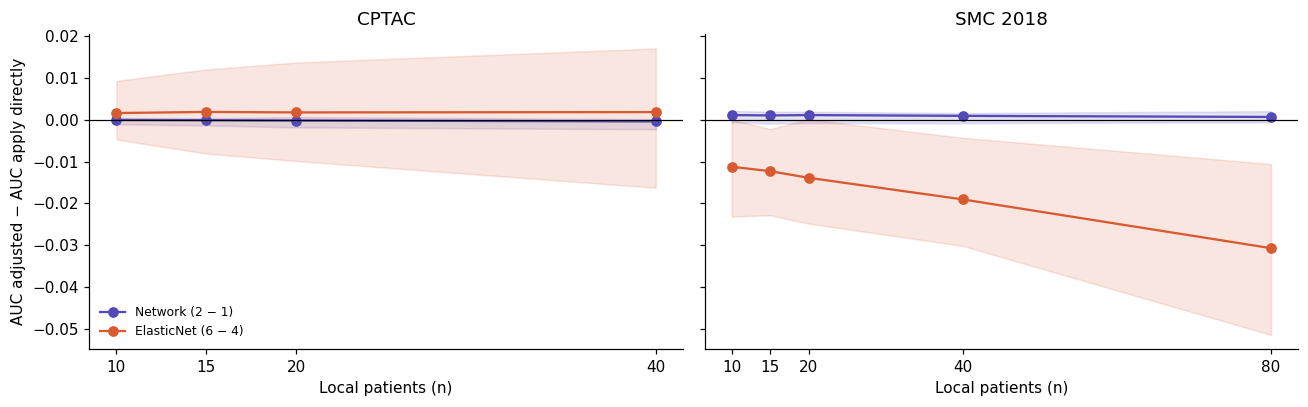

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, TARGETS):
    for (fam, d), color in zip(diffs.items(), (NET, ENET)):
        t = d.loc[name]
        ax.plot(t.index, t["mean"], marker="o", color=color, label=fam)
        ax.fill_between(t.index, t["min"], t["max"], color=color, alpha=0.15)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Local patients (n)")
    ax.set_xticks(diffs["Network (2 − 1)"].loc[name].index)
axes[0].set_ylabel("AUC adjusted − AUC apply directly")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "09_difference_vs_n.png", bbox_inches="tight")

**Figure 09-6 · How to read it:** the line is the mean of the 5 exams, and the band goes from the lowest to the highest exam. Above 0, adjusting with the local patients raises the AUC compared with applying the model directly. The rule gives n = 10 in two cases, but the difference there is only 0.001 to 0.002. In practice, adjusting does not change the AUC.

## Step 5 · Secondary results

### Stability per patient
For each exam patient: the SD of its probability of being mutated across the 100 repetitions, with n = 10.

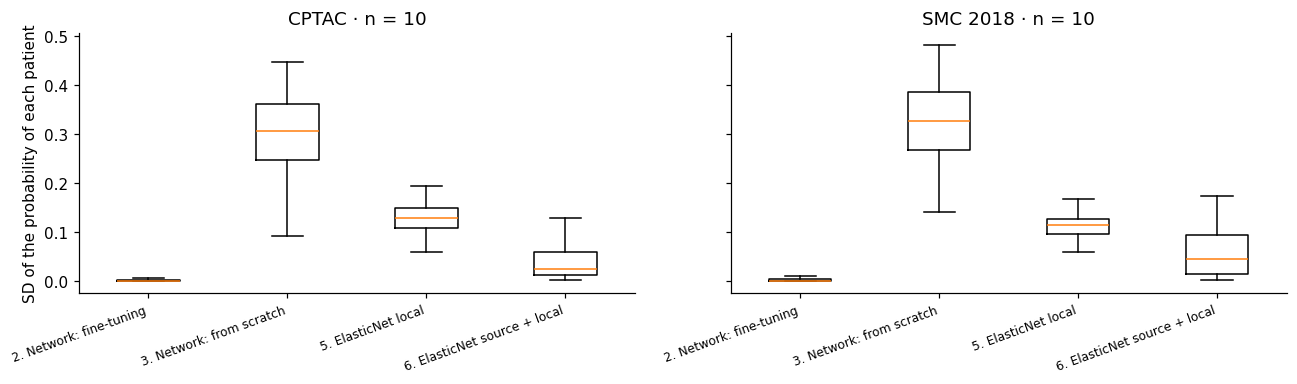

In [14]:
prob_e = pd.read_parquet(EXP / "prob_elasticnet.parquet")
prob_r = pd.read_parquet(EXP / "prob_red.parquet")
prob = pd.concat([prob_e[prob_e.peso_locales.isna() | (prob_e.peso_locales == 0.5)],
                  prob_r[prob_r.variante == "principal"]], ignore_index=True)
y_all = pd.concat([pd.read_csv(DATA / f"y_{FILES[c]}.csv", index_col=0).y for c in TARGETS])
prob["y"] = prob.muestra.map(y_all)  # the probability files do not store the label
assert prob.y.notna().all()

per_patient = (prob[(prob.n == 10)].groupby(["cohorte", "estrategia", "examen", "muestra"]).prob.std().reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = per_patient[per_patient.cohorte == name]
    ax.boxplot([d[d.estrategia == k].prob for k in LOCAL], showfliers=False)
    ax.set_xticks(range(1, 5), [NAMES[k] for k in LOCAL], rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{name} · n = 10")
axes[0].set_ylabel("SD of the probability of each patient")
plt.tight_layout()
fig.savefig(FIG / "09_prob_per_patient.png", bbox_inches="tight")

**Figure 09-7 · How to read it:** each box summarizes the exam patients. Even when two strategies have a similar AUC, the probability given to the same patient can change a lot depending on which 10 local patients were drawn. Lower = more stable predictions for each patient.

### Calibration

The AUC says whether the model **ranks** patients well. **Calibration** says whether its **probabilities can be trusted**. In other words: of the patients that get a probability of 0.7, are about 70% really mutated? The patients are split into 10 groups by their probability, and the mean probability of each group is compared with the real proportion of mutated tumors. All repetitions and exams are pooled, with n = 10 for the strategies that use local patients.

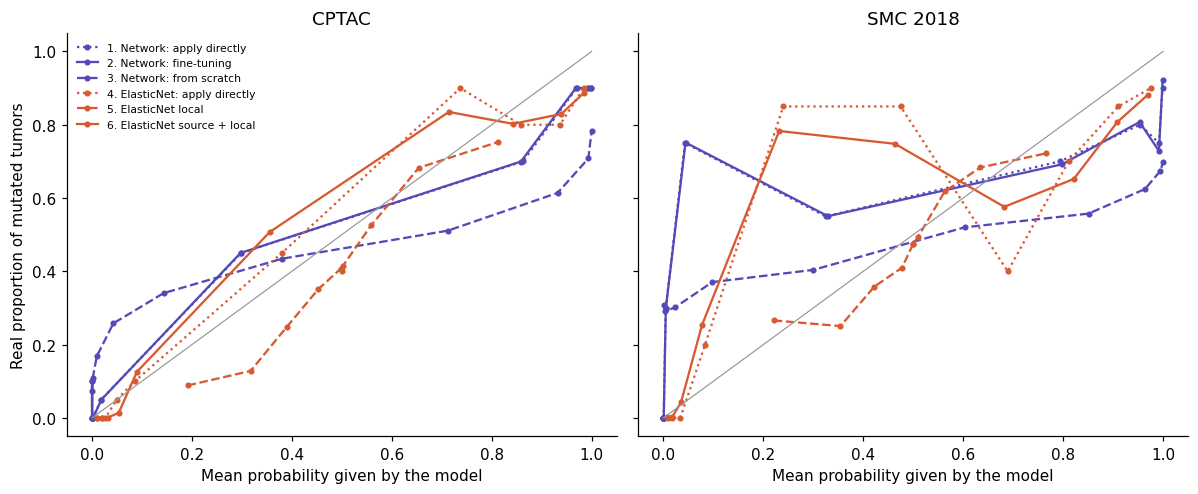

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
show = {1: (NET, ":"), 2: (NET, "-"), 3: (NET, "--"), 4: (ENET, ":"), 5: (ENET, "--"), 6: (ENET, "-")}
for ax, name in zip(axes, TARGETS):
    d = prob[(prob.cohorte == name) & (prob.n.isin([0, 10]))]
    for k, (color, ls) in show.items():
        v = d[d.estrategia == k]
        observed, predicted = calibration_curve(v.y, v.prob, n_bins=10, strategy="quantile")
        ax.plot(predicted, observed, color=color, ls=ls, marker=".", label=NAMES[k])
    ax.plot([0, 1], [0, 1], color="#999999", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Mean probability given by the model")
axes[0].set_ylabel("Real proportion of mutated tumors")
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
fig.savefig(FIG / "09_calibration.png", bbox_inches="tight")

**Figure 09-8 · How to read it:** the gray diagonal is perfect calibration. A curve below the diagonal means that the model gives probabilities higher than the real proportion (it overstates). A curve above means the opposite. Notebook 06 showed that the network becomes overconfident during training, and this figure shows whether that also happens in CPTAC and SMC.

### Confusion matrix

The AUC does not use a threshold. To classify each patient as "mutated" or "not mutated", a threshold is needed. The threshold is **0.5**, fixed before looking at the results. The reason is that the models were trained with class weights, so 0.5 is the neutral point. No other threshold is tested.

- **Sensitivity:** of the mutated tumors, the proportion the model classifies as mutated.
- **Specificity:** of the not mutated tumors, the proportion the model classifies as not mutated.

Each matrix shows **patients per exam of 40** (CPTAC: 16 mutated and 24 not mutated; SMC: 19 and 21), as the mean rounded to whole patients. Strategies 1 and 4: mean of the 5 exams. Strategies 2, 3, 5 and 6: mean of the 500 models with n = 10.

sensitivity  specificity  accuracy
cohorte  estrategia                                    
CPTAC    1                 0.912        0.900     0.905
         2                 0.907        0.900     0.903
         3                 0.668        0.759     0.722
         4                 0.925        0.883     0.900
         5                 0.550        0.773     0.684
         6                 0.897        0.881     0.888
SMC 2018 1                 0.663        0.838     0.755
         2                 0.671        0.833     0.756
         3                 0.628        0.650     0.640
         4                 0.653        0.762     0.710
         5                 0.612        0.635     0.624
         6                 0.662        0.769     0.718

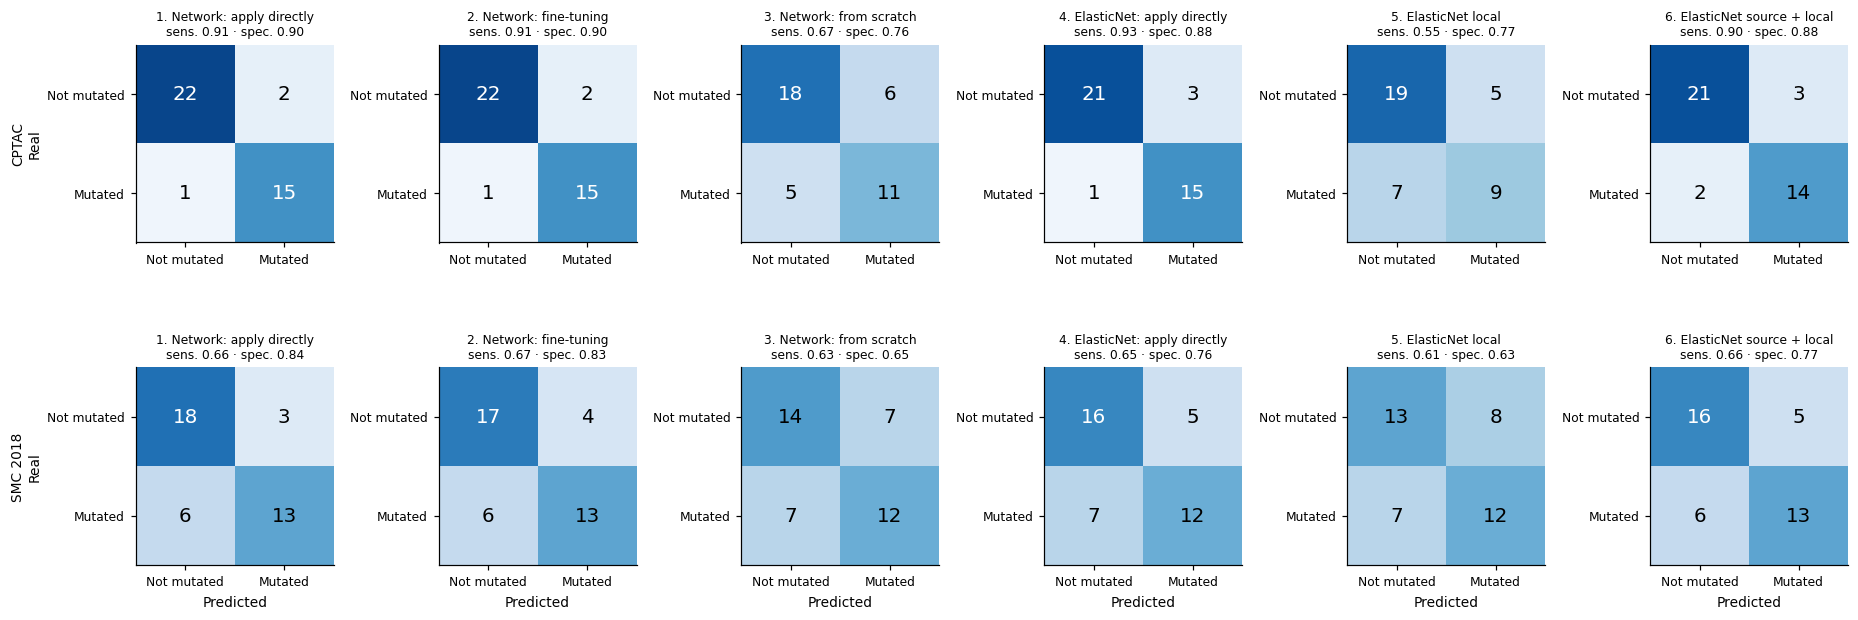

In [16]:
THRESHOLD = 0.5
cm = prob[prob.n.isin([0, 10])].assign(pred=lambda d: (d.prob >= THRESHOLD).astype(int))
cm["tp"] = (cm.pred == 1) & (cm.y == 1)
cm["fn"] = (cm.pred == 0) & (cm.y == 1)
cm["fp"] = (cm.pred == 1) & (cm.y == 0)
cm["tn"] = (cm.pred == 0) & (cm.y == 0)
per_model = cm.groupby(["cohorte", "estrategia", "examen", "repeticion"])[["tp", "fn", "fp", "tn"]].sum()
per_model["sensitivity"] = per_model.tp / (per_model.tp + per_model.fn)
per_model["specificity"] = per_model.tn / (per_model.tn + per_model.fp)
per_model["accuracy"] = (per_model.tp + per_model.tn) / per_model[["tp", "fn", "fp", "tn"]].sum(axis=1)
confusion = per_model.groupby(["cohorte", "estrategia"]).agg(["mean", "std"])
confusion.round(3).to_csv(TAB / "09_confusion.csv")

fig, axes = plt.subplots(2, 6, figsize=(17, 6.2))
for i, name in enumerate(TARGETS):
    for j, k in enumerate([1, 2, 3, 4, 5, 6]):
        ax = axes[i, j]
        c = confusion.loc[(name, k)]
        # Whole patients: errors are rounded and hits are the rest, so each row adds up to the exam.
        n_wt, n_mut = round(c[("tn", "mean")] + c[("fp", "mean")]), round(c[("tp", "mean")] + c[("fn", "mean")])
        fp, fn = round(c[("fp", "mean")]), round(c[("fn", "mean")])
        m = np.array([[n_wt - fp, fp], [fn, n_mut - fn]])
        ax.imshow(m, cmap="Blues", vmin=0, vmax=24)
        for (r, q), v in np.ndenumerate(m):
            ax.text(q, r, f"{v}", ha="center", va="center", fontsize=13, color="white" if v > 14 else "black")
        ax.set_xticks([0, 1], ["Not mutated", "Mutated"], fontsize=8)
        ax.set_yticks([0, 1], ["Not mutated", "Mutated"], fontsize=8)
        ax.set_title(f"{NAMES[k]}\nsens. {c[('sensitivity', 'mean')]:.2f} · spec. {c[('specificity', 'mean')]:.2f}", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{name}\nReal", fontsize=9)
        if i == 1:
            ax.set_xlabel("Predicted", fontsize=9)
plt.tight_layout()
fig.savefig(FIG / "09_confusion_matrix.png", bbox_inches="tight")
confusion.xs("mean", axis=1, level=1)[["sensitivity", "specificity", "accuracy"]].round(3)

**Figure 09-9 · How to read it:** rows = real status; columns = what the model predicts with a threshold of 0.5. The diagonal (top left and bottom right) are the hits. Bottom left = mutated tumors that the model misses (false negatives). Top right = not mutated tumors classified as mutated (false positives). The sensitivity and specificity in the title are exact.

### The cohorts before and after normalization

Each point is a patient, placed by its expression with a **principal component analysis (PCA)**. PCA summarizes the 18,040 genes in the 2 axes that separate the patients the most. No TP53 label is used. The figure shows the problem that the transfer has to solve: the cohorts are different.

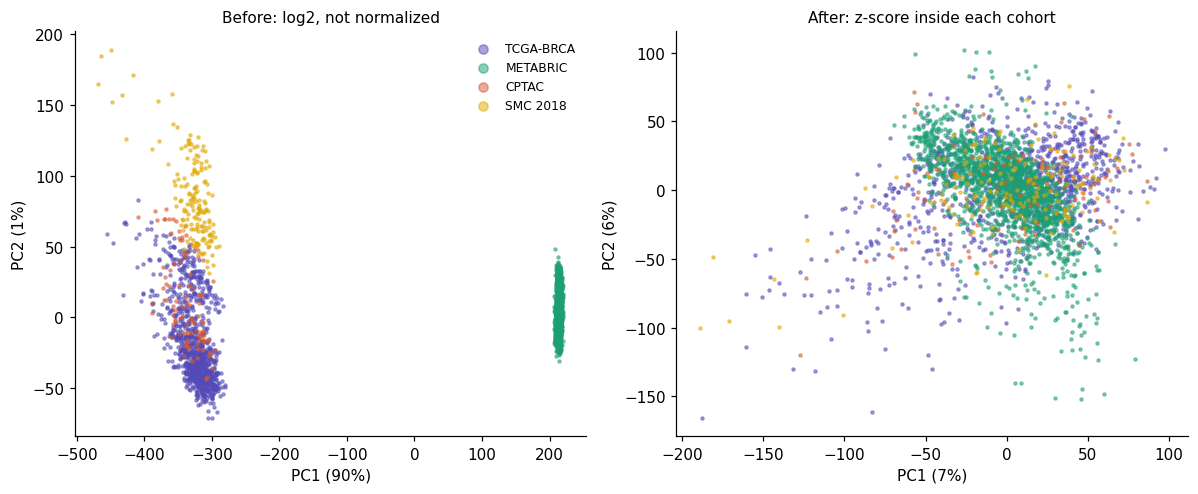

In [17]:
cohorts = ["TCGA-BRCA", "METABRIC", "CPTAC", "SMC 2018"]
raw, scaled, labels = [], [], []
for c in cohorts:
    x, _ = cargar(c)
    x = x.fillna(x.median())
    raw.append(x.to_numpy(np.float32))
    scaled.append(zscore(x, x.index).to_numpy())
    labels += [c] * len(x)
labels = np.array(labels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
palette = dict(zip(cohorts, ["#534AB7", "#1D9E75", "#D85A30", "#E0A800"]))
for ax, data, title in zip(axes, (np.vstack(raw), np.vstack(scaled)),
                           ("Before: log2, not normalized", "After: z-score inside each cohort")):
    pcs = PCA(2, svd_solver="randomized", random_state=0).fit(data)
    xy = pcs.transform(data)
    for c in cohorts:
        ax.scatter(*xy[labels == c].T, s=4, alpha=0.5, color=palette[c], label=c)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f"PC1 ({100 * pcs.explained_variance_ratio_[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({100 * pcs.explained_variance_ratio_[1]:.0f}%)")
axes[0].legend(frameon=False, fontsize=8, markerscale=3)
plt.tight_layout()
fig.savefig(FIG / "09_pca_cohorts.png", bbox_inches="tight")

**Figure 09-10 · How to read it:** on the left, METABRIC (microarray) is far from the RNA-seq cohorts. The first axis explains 90% of the variation and it only reflects the platform. On the right, after the z-score inside each cohort, the four cohorts mix. For this figure CPTAC and SMC are normalized with all their patients. In the experiment, only the patients outside each exam were used, which gives almost the same result.

## Step 6 · Sensitivity analyses

They were defined before running the experiment. The primary comparisons (n = 10) are repeated changing only one thing at a time:
1. **Fine-tuning with learning rate 1e-4** instead of 1e-5, with 10 epochs. This setting does change the network (decision of 14-Oct-2026).
2. **Strategy 6 with the local patients at 25% and at 10%** of the weight, instead of 50%.

In [18]:
def variant(strategy, rows):
    return pd.concat([main[main.estrategia != strategy], rows[keys + ["auc"]]], ignore_index=True)


sens = []
alt_ft = variant(2, red[(red.estrategia == 2) & (red.variante == "sensibilidad")])
for name in TARGETS:
    for a, b in PRIMARY:
        sens.append({"version": "fine-tuning with learning rate 1e-4", **compare(alt_ft, a, b, 10, name)})
for w in (0.25, 0.10):
    alt_w = variant(6, enet[(enet.estrategia == 6) & (enet.peso_locales == w)])
    for name in TARGETS:
        sens.append({"version": f"strategy 6 with local patients at {int(w * 100)}%", **compare(alt_w, 2, 6, 10, name)})
sens = pd.DataFrame(sens)
sens.round(4).to_csv(TAB / "09_sensitivity.csv", index=False)

auc_ft = summarize(alt_ft[alt_ft.estrategia == 2]).rename(columns=lambda c: c + " (learning rate 1e-4)")
display(sens[["version", "cohort", "comparison", "SD strategy a", "SD strategy b", "SD reduction (%)", "combined Z", "p"]].round(4))
pd.concat([summary.xs(2, level="estrategia"), auc_ft.xs(2, level="estrategia")], axis=1).round(3)

,version,cohort,comparison,SD strategy a,SD strategy b,SD reduction (%),combined Z,p
0,fine-tuning with learning rate 1e-4,CPTAC,2 vs 3,0.0087,0.1162,92.4726,59.9419,0.0000
1,fine-tuning with learning rate 1e-4,CPTAC,2 vs 6,0.0087,0.0100,12.4110,3.6577,0.0003
2,fine-tuning with learning rate 1e-4,SMC 2018,2 vs 3,0.0087,0.0935,90.6915,53.0877,0.0000
3,fine-tuning with learning rate 1e-4,SMC 2018,2 vs 6,0.0087,0.0151,42.3145,13.2700,0.0000
4,strategy 6 with local patients at 25%,CPTAC,2 vs 6,0.0009,0.0081,88.3811,49.3228,0.0000
5,strategy 6 with local patients at 25%,SMC 2018,2 vs 6,0.0017,0.0117,85.2925,42.3158,0.0000
6,strategy 6 with local patients at 10%,CPTAC,2 vs 6,0.0009,0.0063,85.1159,43.5424,0.0000
7,strategy 6 with local patients at 10%,SMC 2018,2 vs 6,0.0017,0.0088,80.3638,36.0302,0.0000


mean AUC  SD across repetitions  mean AUC (learning rate 1e-4)  \
cohorte  n                                                                    
CPTAC    10     0.933                  0.001                          0.933   
         15     0.933                  0.001                          0.933   
         20     0.933                  0.001                          0.934   
         40     0.933                  0.000                          0.935   
SMC 2018 10     0.867                  0.002                          0.867   
         15     0.867                  0.002                          0.868   
         20     0.867                  0.002                          0.869   
         40     0.867                  0.001                          0.870   
         80     0.866                  0.001                          0.870   

             SD across repetitions (learning rate 1e-4)  
cohorte  n                                               
CPTAC    10                                       0.009  
         15                                       0.007  
         20                                       0.005  
         40                                       0.003  
SMC 2018 10                                       0.009  
         15                                       0.008  
         20                                       0.007  
         40                                       0.005  
         80                                       0.004

**How to read it:** if the sign and the significance of the comparisons do not change with these versions, the conclusion does not depend on the learning rate of fine-tuning or on the weight of the local patients. The second table compares the AUC of fine-tuning with the two learning rates.

### How much fine-tuning reduces the SD

SD reduction of strategy 2 against strategies 3, 5 and 6, with n = 10, for the two fine-tuning settings: the main one (learning rate 1e-5) and the sensitivity one (learning rate 1e-4).

,setting,cohort,comparison,SD strategy a,SD strategy b,SD reduction (%),min reduction (%),max reduction (%)
0,main (learning rate 1e-5),CPTAC,2 vs 3,0.001,0.116,99.187,98.976,99.629
1,main (learning rate 1e-5),CPTAC,2 vs 5,0.001,0.157,99.396,99.149,99.766
2,main (learning rate 1e-5),CPTAC,2 vs 6,0.001,0.010,90.542,78.179,95.547
3,main (learning rate 1e-5),SMC 2018,2 vs 3,0.002,0.093,98.158,97.153,99.013
4,main (learning rate 1e-5),SMC 2018,2 vs 5,0.002,0.116,98.517,97.868,99.129
5,main (learning rate 1e-5),SMC 2018,2 vs 6,0.002,0.015,88.586,81.202,91.683
6,sensitivity (learning rate 1e-4),CPTAC,2 vs 3,0.009,0.116,92.473,88.056,94.035
7,sensitivity (learning rate 1e-4),CPTAC,2 vs 5,0.009,0.157,94.411,90.876,96.243
8,sensitivity (learning rate 1e-4),CPTAC,2 vs 6,0.009,0.010,12.411,-53.969,37.686
9,sensitivity (learning rate 1e-4),SMC 2018,2 vs 3,0.009,0.093,90.691,86.074,94.419


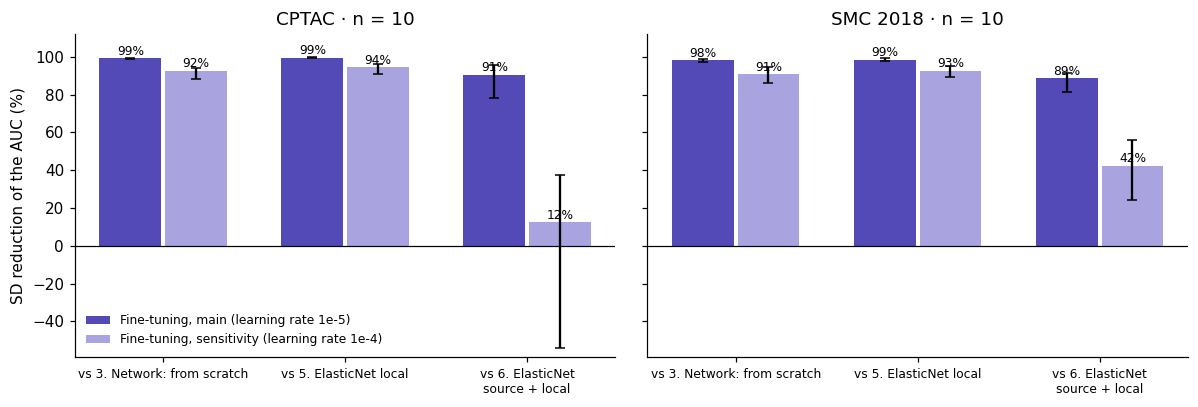

In [19]:
cuts = []
for label, df in (("main (learning rate 1e-5)", main), ("sensitivity (learning rate 1e-4)", alt_ft)):
    for name in TARGETS:
        for b in (3, 5, 6):
            cuts.append({"setting": label, **compare(df, 2, b, 10, name)})
cuts = pd.DataFrame(cuts)
cuts.round(1).to_csv(TAB / "09_sd_reduction.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, name in zip(axes, TARGETS):
    for k, (label, color) in enumerate((("main (learning rate 1e-5)", NET), ("sensitivity (learning rate 1e-4)", "#A9A3E0"))):
        d = cuts[(cuts.cohort == name) & (cuts["setting"] == label)]
        x = np.arange(3) + (k - 0.5) * 0.36
        y = d["SD reduction (%)"].to_numpy()
        err = [y - d["min reduction (%)"].to_numpy(), d["max reduction (%)"].to_numpy() - y]
        ax.bar(x, y, width=0.34, color=color, yerr=err, capsize=3, label=f"Fine-tuning, {label}")
        for xi, yi in zip(x, y):
            ax.text(xi, yi + 2, f"{yi:.0f}%", ha="center", fontsize=8)
    ax.set_xticks(range(3), ["vs 3. Network: from scratch", "vs 5. ElasticNet local", "vs 6. ElasticNet\nsource + local"], fontsize=8)
    ax.set_ylim(min(-5, cuts["min reduction (%)"].min() - 5), 112)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{name} · n = 10")
axes[0].set_ylabel("SD reduction of the AUC (%)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
fig.savefig(FIG / "09_sd_reduction.png", bbox_inches="tight")
cuts[["setting", "cohort", "comparison", "SD strategy a", "SD strategy b", "SD reduction (%)",
      "min reduction (%)", "max reduction (%)"]].round(3)

**Figure 09-11 · How to read it:** each bar says by which percentage fine-tuning varies less than the other strategy. 100% = it does not vary at all; 0% = it varies the same. The black lines go from the exam with the smallest reduction to the exam with the largest one. Below 0, fine-tuning varied more than the other strategy in that exam. The main setting barely changes the network, which is why its reduction is close to 100%. The sensitivity setting does change the network, so it is the more cautious estimate.

## Step 7 · Summary in numbers

One paragraph per cohort, built from the tables above. It is the starting point for the Results section of the paper.

In [20]:
for name in TARGETS:
    s = summary.loc[name]
    pr = primary[primary.cohort == name].set_index("comparison")
    rec = recommended[recommended.cohort == name].set_index("family")["n by the rule"]
    print(f"""{name}: applying the source model directly gave an AUC of {s.loc[(1, 0), 'mean AUC']:.3f} with the network and {s.loc[(4, 0), 'mean AUC']:.3f} with ElasticNet.
With 10 local patients, network fine-tuning gave {s.loc[(2, 10), 'mean AUC']:.3f} (SD {s.loc[(2, 10), 'SD across repetitions']:.3f}), \
the network from scratch {s.loc[(3, 10), 'mean AUC']:.3f} (SD {s.loc[(3, 10), 'SD across repetitions']:.3f}), \
local ElasticNet {s.loc[(5, 10), 'mean AUC']:.3f} (SD {s.loc[(5, 10), 'SD across repetitions']:.3f}) \
and ElasticNet source + local {s.loc[(6, 10), 'mean AUC']:.3f} (SD {s.loc[(6, 10), 'SD across repetitions']:.3f}).
Stability, 2 vs 3: SD reduction {pr.loc['2 vs 3', 'SD reduction (%)']:.0f}%, p = {pr.loc['2 vs 3', 'p']:.3g}. \
2 vs 6: SD reduction {pr.loc['2 vs 6', 'SD reduction (%)']:.0f}%, p = {pr.loc['2 vs 6', 'p']:.3g}.
Number of local patients by the rule: network {rec['Network (2 − 1)']}, ElasticNet {rec['ElasticNet (6 − 4)']}.
""")

CPTAC: applying the source model directly gave an AUC of 0.933 with the network and 0.930 with ElasticNet.
With 10 local patients, network fine-tuning gave 0.933 (SD 0.001), the network from scratch 0.789 (SD 0.116), local ElasticNet 0.714 (SD 0.157) and ElasticNet source + local 0.931 (SD 0.010).
Stability, 2 vs 3: SD reduction 99%, p = 0. 2 vs 6: SD reduction 91%, p = 0.
Number of local patients by the rule: network none, ElasticNet 10.

SMC 2018: applying the source model directly gave an AUC of 0.866 with the network and 0.865 with ElasticNet.
With 10 local patients, network fine-tuning gave 0.867 (SD 0.002), the network from scratch 0.677 (SD 0.093), local ElasticNet 0.654 (SD 0.116) and ElasticNet source + local 0.853 (SD 0.015).
Stability, 2 vs 3: SD reduction 98%, p = 0. 2 vs 6: SD reduction 89%, p = 0.
Number of local patients by the rule: network 10, ElasticNet none.

